# 03. Обучение трёх детекторов

Выход: plain/natural/adversarial best.pt, last.pt, история и
validation.

папка `notebooks_colab_full`
в `MyDrive/ML6/`. Исходные видео и старые результаты остаются в прежних папках.
Вычисления читают локальные кадры; результаты нового запуска пишутся в `runs/RUN_ID/`.

In [ ]:
import sys, os, subprocess, importlib.util
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or Path('/content').is_dir()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/ML6')
else:
    PROJECT = Path('D:/ML6')
RUN_ID = 'blue_aug_20261112_v2'  # одинаковый во всех 10 ноутбуках; старый run не меняем
BUNDLE = PROJECT / 'notebooks_colab_full'
assert (BUNDLE / 'tracking_lab.py').is_file(), BUNDLE
packages = {'scipy':'scipy', 'pandas':'pandas', 'cv2':'opencv-python-headless',
    'matplotlib':'matplotlib', 'tqdm':'tqdm', 'trackeval':'trackeval==1.3.0',
    'cryptography':'cryptography', 'imageio':'imageio', 'imageio_ffmpeg':'imageio-ffmpeg'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
# Совместимую пару torch/torchvision предоставляет Colab; автоматически её не заменяем.
sys.path.insert(0, str(BUNDLE))
import tracking_lab as tl
assert Path(tl.__file__).resolve() == (BUNDLE / 'tracking_lab.py').resolve(), 'Перезапустите runtime: загружен старый модуль'
assert tl.SCHEMA == 4, 'Перезапустите runtime после обновления исходного кода'
import torch, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Video, HTML, Image
lab = tl.Lab(PROJECT, RUN_ID)
torch.hub.set_dir(str(PROJECT / 'pretrained_cache'))
display(pd.Series(lab.environment(), name='Среда'))
print('Запуск:', RUN_ID, '| Результаты:', lab.root)

Mounted at /content/drive


,Среда
python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
packages,"{'torch': '2.14.1+cu130', 'torchvision': '0.29..."
device,cuda
gpu,NVIDIA L4


Запуск: blue_aug_20261112_v2 | Результаты: /content/drive/MyDrive/ML6/runs/blue_aug_20261112_v2


Восстановление кадров из архивов на Drive в `/content` с SHA256 каждого JPEG.
Checkpoint, manifest и архивы остаются на Drive.


In [ ]:
LOCAL = '/content/ml6_full_frames' if IN_COLAB else str(lab.path('local_frames'))
tl.cache_frames(lab, LOCAL, splits=('train','val','dev'))
print('Кадры:', lab.frame_cache_root)

Локальный кэш:   0%|          | 0/131 [00:00<?, ?архив/s]

Архив → /content:   0%|          | 0.00/26.1M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/27.2M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/304M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/61.9M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/4.66M [00:00<?, ?B/s]

... (103 outputs left out)

Архив → /content:   0%|          | 0.00/9.88M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/154M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/29.2M [00:00<?, ?B/s]

Кадры: /content/ml6_full_frames


У всех вариантов один порядок сбалансированных frame slots, все train-видео
попадают в каждую логическую эпоху. Один пример — одно воздействие из настраиваемой
смеси 40/15/10/5/5/5/15/5 после адаптации. В natural доля PGD переносится в clean;
в plain все примеры обычные. Перекрытия и оптимизированные патчи учитываются раздельно.
Мини-батч детектора = 1, FP32, checkpoint каждые 100 шагов.
Лучшие веса выбираются одинаковым средним validation AP50 по восьми отдельным условиям.
Это AP50 по полному ранжированию score≥0,01, не COCO mAP50:95.

In [ ]:
assert lab.device.type == 'cuda'
for variant in tl.VARIANTS:
    model = tl.train_detector(lab, variant)
    del model
    torch.cuda.empty_cache()

plain детектор 1:   0%|          | 0/1500 [00:00<?, ?шаг/s]

 scenario     AP50  precision   recall  small_recall  small_gt  attack_gradient
    clean 0.819450   0.638009 0.819767      0.709571       303         0.000000
    photo 0.822380   0.642468 0.823256      0.726073       303         0.000000
     jpeg 0.815835   0.653846 0.810465      0.693069       303         0.000000
    noise 0.815688   0.649446 0.818605      0.699670       303         0.000000
     blur 0.807050   0.660305 0.804651      0.669967       303         0.000000
 geometry 0.819525   0.649312 0.805116      0.662791       258         0.000000
occlusion 0.820067   0.631485 0.820930      0.709571       303         0.000000
      pgd 0.000133   0.004080 0.018605      0.006601       303         0.000938


plain детектор 2:   0%|          | 0/1500 [00:00<?, ?шаг/s]

 scenario     AP50  precision   recall  small_recall  small_gt  attack_gradient
    clean 0.819738   0.720083 0.804651      0.696370       303         0.000000
    photo 0.816253   0.717549 0.803488      0.693069       303         0.000000
     jpeg 0.815985   0.721931 0.800000      0.666667       303         0.000000
    noise 0.816850   0.730526 0.806977      0.696370       303         0.000000
     blur 0.806137   0.717597 0.791860      0.636964       303         0.000000
 geometry 0.826067   0.734967 0.803898      0.670543       258         0.000000
occlusion 0.818095   0.713990 0.801163      0.693069       303         0.000000
      pgd 0.000603   0.003636 0.015116      0.000000       303         0.001245


plain детектор 3:   0%|          | 0/1500 [00:00<?, ?шаг/s]

 scenario     AP50  precision   recall  small_recall  small_gt  attack_gradient
    clean 0.817928   0.741062 0.795349      0.683168       303           0.0000
    photo 0.819229   0.735991 0.794186      0.676568       303           0.0000
     jpeg 0.821880   0.738661 0.795349      0.666667       303           0.0000
    noise 0.821683   0.737069 0.795349      0.663366       303           0.0000
     blur 0.799664   0.714903 0.769767      0.613861       303           0.0000
 geometry 0.814257   0.733708 0.795371      0.658915       258           0.0000
occlusion 0.817846   0.738378 0.794186      0.679868       303           0.0000
      pgd 0.000044   0.001179 0.004651      0.000000       303           0.0013


... (26 outputs left out)

adversarial детектор 5:   0%|          | 0/1500 [00:00<?, ?шаг/s]

 scenario     AP50  precision   recall  small_recall  small_gt  attack_gradient
    clean 0.808371   0.756912 0.763953      0.627063       303         0.000000
    photo 0.808523   0.760046 0.769767      0.636964       303         0.000000
     jpeg 0.800110   0.762016 0.755814      0.607261       303         0.000000
    noise 0.804630   0.767497 0.752326      0.617162       303         0.000000
     blur 0.795727   0.721854 0.760465      0.600660       303         0.000000
 geometry 0.811085   0.736239 0.781973      0.651163       258         0.000000
occlusion 0.804954   0.753740 0.761628      0.627063       303         0.000000
      pgd 0.042349   0.040014 0.133721      0.009901       303         0.000198


adversarial детектор 6:   0%|          | 0/1500 [00:00<?, ?шаг/s]

 scenario     AP50  precision   recall  small_recall  small_gt  attack_gradient
    clean 0.793428   0.759107 0.751163      0.597360       303         0.000000
    photo 0.792846   0.755269 0.750000      0.597360       303         0.000000
     jpeg 0.776427   0.756303 0.732558      0.557756       303         0.000000
    noise 0.781009   0.764988 0.741860      0.584158       303         0.000000
     blur 0.785241   0.723404 0.751163      0.580858       303         0.000000
 geometry 0.803267   0.743831 0.771011      0.624031       258         0.000000
occlusion 0.788325   0.757109 0.743023      0.594059       303         0.000000
      pgd 0.037890   0.042642 0.131395      0.023102       303         0.000201


,Воздействие,Примеров
0,Обычные,9000


,Вариант,Уникальных кадров использовано,Уникальных видео использовано,Чистых кадров доступно
0,plain,5848,94,12031


,,,Фактически применено
epoch,requested_mode,mode,
0,clean,clean,1500
1,clean,clean,1500
2,clean,clean,1500
3,clean,clean,1500
4,clean,clean,1500
5,clean,clean,1500


,Потеря,Секунд/шаг
mode,,
clean,0.538679,0.195009


,Воздействие,Примеров
0,JPEG,895
1,Геометрия,486
2,Обычные,5016
3,Перекрытие,415
4,Размытие,433
5,Шум,432
6,Яркость / контраст / гамма,1323


,Вариант,Уникальных кадров использовано,Уникальных видео использовано,Чистых кадров доступно
0,natural,5848,94,12031


... (2 outputs left out)

,Воздействие,Примеров
0,Adversarial-патч,36
1,JPEG,851
2,PGD,914
3,Геометрия,464
4,Обычные,4158
5,Перекрытие,373
6,Размытие,456
7,Шум,442
8,Яркость / контраст / гамма,1306


,Вариант,Уникальных кадров использовано,Уникальных видео использовано,Чистых кадров доступно
0,adversarial,5848,94,12031


Фактически применено
epoch requested_mode mode                           
0     blur           blur                         58
      clean          clean                       889
      geometry       geometry                     74
      jpeg           jpeg                        125
      noise          noise                        73
      occlusion      clean                         1
                     occlusion                    74
      photo          photo                       206
1     blur           blur                         69
      clean          clean                       757
      geometry       geometry                     95
      jpeg           jpeg                        146
      noise          noise                        69
      occlusion      clean                         1
                     occlusion                    63
      patch          patch                         2
      pgd            pgd                          59
      photo          photo                       239
2     blur           blur                         76
      clean          clean                       671
      geometry       geometry                     63
      jpeg           jpeg                        145
      noise          noise                        81
      occlusion      clean                         2
                     occlusion                    69
      patch          patch                         7
      pgd            pgd                         175
      photo          photo                       211
3     blur           blur                         89
      clean          clean                       584
      geometry       geometry                     83
      jpeg           jpeg                        136
      noise          noise                        82
      occlusion      clean                         1
                     occlusion                    56
      patch          clean                         1
                     patch                         9
      pgd            pgd                         249
      photo          photo                       210
4     blur           blur                         79
      clean          clean                       619
      geometry       geometry                     79
      jpeg           jpeg                        147
      noise          noise                        70
      occlusion      occlusion                    62
      patch          clean                         1
                     patch                        12
      pgd            pgd                         227
      photo          photo                       204
5     blur           blur                         85
      clean          clean                       628
      geometry       geometry                     70
      jpeg           jpeg                        152
      noise          noise                        67
      occlusion      clean                         2
                     occlusion                    49
      patch          clean                         1
                     patch                         6
      pgd            pgd                         204
      photo          photo                       236

,Потеря,Секунд/шаг
mode,,
blur,0.594063,0.195505
clean,0.559212,0.193401
geometry,0.659518,0.194369
jpeg,0.567682,0.208559
noise,0.556186,0.241471
occlusion,0.572275,0.193183
patch,0.539383,1.225672
pgd,1.704260,0.915531
photo,0.560307,0.211929


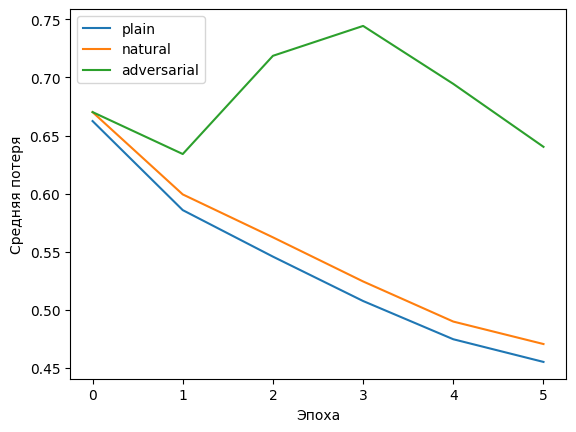

,Сценарий,AP50,precision,recall,Recall малых людей,small_gt,attack_gradient,Вариант,Эпоха
0,clean,0.819450,0.638009,0.819767,0.709571,303,0.000000,plain,1
1,photo,0.822380,0.642468,0.823256,0.726073,303,0.000000,plain,1
2,jpeg,0.815835,0.653846,0.810465,0.693069,303,0.000000,plain,1
3,noise,0.815688,0.649446,0.818605,0.699670,303,0.000000,plain,1
4,blur,0.807050,0.660305,0.804651,0.669967,303,0.000000,plain,1
...,...,...,...,...,...,...,...,...,...
139,noise,0.781009,0.764988,0.741860,0.584158,303,0.000000,adversarial,6
140,blur,0.785241,0.723404,0.751163,0.580858,303,0.000000,adversarial,6
141,geometry,0.803267,0.743831,0.771011,0.624031,258,0.000000,adversarial,6
142,occlusion,0.788325,0.757109,0.743023,0.594059,303,0.000000,adversarial,6


,variant,epoch,scenario,Изменение AP50,Изменение recall малых
0,plain,1,clean,0.018263,0.095710
1,plain,1,photo,0.019597,0.102310
2,plain,1,jpeg,0.032707,0.075908
3,plain,1,noise,0.011838,0.072607
4,plain,1,blur,0.020121,0.089109
...,...,...,...,...,...
139,adversarial,6,noise,-0.022841,-0.042904
140,adversarial,6,blur,-0.001688,0.000000
141,adversarial,6,geometry,0.018027,0.015504
142,adversarial,6,occlusion,-0.010111,-0.019802


In [ ]:
rows=[]
for variant in tl.VARIANTS:
    folder=tl.model_path(lab,'detector',variant).parent
    history=pd.read_csv(folder/'history.csv')
    display(pd.read_csv(folder/'augmentation_counts.csv'))
    display(pd.DataFrame([{'Вариант':variant,'Уникальных кадров использовано':len(history[['video','frame_idx']].drop_duplicates()),
        'Уникальных видео использовано':history.video.nunique(),'Чистых кадров доступно':len(lab.records('train'))}]))
    display(history.groupby(['epoch','requested_mode','mode']).size().rename('Фактически применено').to_frame())
    display(history.groupby('mode')[['loss','seconds']].mean().rename(columns={'loss':'Потеря','seconds':'Секунд/шаг'}))
    history.groupby('epoch').loss.mean().plot(label=variant)
    for p in sorted(folder.glob('validation_epoch_*.csv')):
        t=pd.read_csv(p); t['variant']=variant; t['epoch']=int(p.stem.rsplit('_',1)[1]); rows.append(t)
plt.xlabel('Эпоха'); plt.ylabel('Средняя потеря'); plt.legend(); plt.show()
validation=pd.concat(rows,ignore_index=True)
display(validation.rename(columns={'scenario':'Сценарий','variant':'Вариант','epoch':'Эпоха','small_recall':'Recall малых людей'}))
initial=pd.read_csv(lab.path('artifacts/detector_initial_validation.csv'))
forgetting=validation.merge(initial[['scenario','AP50','small_recall']],on='scenario',suffixes=('','_initial'))
forgetting['Изменение AP50']=forgetting.AP50-forgetting.AP50_initial
forgetting['Изменение recall малых']=forgetting.small_recall-forgetting.small_recall_initial
display(forgetting[['variant','epoch','scenario','Изменение AP50','Изменение recall малых']])

natural дал лучший общий результат, но преимущество над plain небольшое.
На обычных кадрах модели находят около 80% людей, под PGD — лишь 2–3%.
Обучение с атаками повышает обнаружение под PGD до 13%, но снижает его на обычных кадрах до 76%.
По текущему критерию для adversarial выбирается вторая эпоха — до заметного роста устойчивости.